# Step 3: Analysis of the anonymised dataset

This notebook repeats the Step 1 analyses (questions A–C from `analysis.ipynb`) on the anonymised release `data/anonymised_dataM_v2.csv` (built in `anonymisation.ipynb`) and compares the outcomes with the raw data.

Every analysis is run on three versions of the data:

| Version | What it is | Purpose |
|---|---|---|
| **Step 1 (raw)** | raw survey with the coding used in `analysis.ipynb` (5 age groups, 3 education groups, 4 ZIPs, 4 marital statuses) | the reference results |
| **raw, release coding** | raw survey recoded exactly like the release (3 age bands, 4 education levels, 2 regions, 2 marital statuses), with no blanking or swapping | shows the cost of the coarser groups |
| **anonymised** | `anonymised_dataM_v2.csv` (also has blanked values and swapped parties) | the released data |

The difference between the last two columns is the effect of suppression and swapping alone, which is the part Step 2 can tune.

**Rule for "too large" (decided before looking at the results):** a difference is too large if a significance verdict at α = 0.05 flips between *raw, release coding* and *anonymised* for any test in A–C, or if an effect size (Cramér's V) changes by more than 0.10.

In [1]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.special import gammaln
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
ALPHA = 0.05
CATS = ["Red", "Green", "Invalid vote"]
VERSION_STYLE = {  # colour + marker, so versions are never told apart by colour alone
    "raw, release coding": {"color": "#1f77b4", "marker": "o"},
    "anonymised": {"color": "#ff7f0e", "marker": "D"},
}

priv = pd.read_excel("data/private_dataM.xlsx")
anon_raw = pd.read_csv("data/anonymised_dataM_v2.csv")
results = pd.read_excel("data/public_data_resultsM.xlsx").rename(columns={"Unnamed: 0": "unit"})
print(anon_raw.shape)
anon_raw.isna().sum()

(200, 7)


sex               18
age_group          0
region            33
education          0
marital_status    15
evote              0
party              0
dtype: int64

## 0. Preparing the three versions
The anonymised release has no exact age, detailed education, ZIP or citizenship, so:
* **Age** is analysed through the age bands, and as an ordinal rank 0/1/2 where Step 1 used exact age (Mann–Whitney test, logistic regression).
* **Education rank** uses the 4 released levels instead of the 8 detailed ones. *Not stated* is excluded, as in Step 1.
* **ZIP** becomes region, and per-ZIP comparisons in (A) become per-region comparisons.
* **Citizenship** is not released, so it cannot be analysed (it was not significant in Step 1).
* **Blank (NA) values** are dropped test by test in the χ² tests. In the logistic regressions they become an *Unknown* level, so no rows are lost.

In [2]:
REGION = {2100: "2100-2200", 2200: "2100-2200", 2300: "2300-2400", 2400: "2300-2400"}
EDU_RELEASE = {
    "Primary education": "Primary",
    "Upper secondary education": "Secondary/VET", "Vocational Education and Training (VET)": "Secondary/VET",
    "Short cycle higher education": "Short/medium higher", "Vocational bachelors educations": "Short/medium higher",
    "Bachelors programmes": "Short/medium higher",
    "Masters programmes": "Long higher", "PhD programmes": "Long higher",
    "Not stated": "Not stated",
}
EDU_LEVELS = ["Primary", "Secondary/VET", "Short/medium higher", "Long higher"]
AGE_BANDS = ["20-39", "40-59", "60+"]

# Step 1 coding (as in analysis.ipynb)
EDU_STEP1 = {
    "Primary education": "Basic", "Upper secondary education": "Basic",
    "Vocational Education and Training (VET)": "Vocational/short", "Short cycle higher education": "Vocational/short",
    "Vocational bachelors educations": "Higher", "Bachelors programmes": "Higher",
    "Masters programmes": "Higher", "PhD programmes": "Higher",
}


def finish(df):
    df = df.copy()
    df["channel"] = df["evote"].map({0: "Paper", 1: "Electronic"})
    return df


# Step 1: raw with the analysis.ipynb coding; columns renamed so attribute names line up across versions
age1 = ((pd.Timestamp("2023-06-01") - priv["dob"]).dt.days / 365.25).astype(int)
step1 = finish(pd.DataFrame({
    "sex": priv["sex"],
    "age_group": pd.cut(age1, [17, 29, 44, 59, 74, 120], labels=["18-29", "30-44", "45-59", "60-74", "75+"]).astype(str),
    "education": priv["education"].map(EDU_STEP1),
    "marital_status": priv["marital_status"],
    "region": priv["zip"].astype(str),
    "evote": priv["evote"], "party": priv["party"],
    "age_rank": age1,                                   # exact age
}))

# raw recoded exactly like the release (same reference date and bands as anonymisation.ipynb)
age2 = ((pd.Timestamp("2025-07-01") - priv["dob"]).dt.days / 365.25).astype(int)
raw_rel = finish(pd.DataFrame({
    "sex": priv["sex"],
    "age_group": pd.cut(age2, [0, 39, 59, 200], labels=AGE_BANDS).astype(str),
    "region": priv["zip"].map(REGION),
    "education": priv["education"].map(EDU_RELEASE),
    "marital_status": np.where(priv["marital_status"] == "Married/separated", "Married/separated", "Not married"),
    "evote": priv["evote"], "party": priv["party"],
}))
anon = finish(anon_raw)
for df in (raw_rel, anon):
    df["age_rank"] = df["age_group"].map({a: i for i, a in enumerate(AGE_BANDS)})
for df in (step1, raw_rel, anon):
    df.loc[df["education"] == "Not stated", "education"] = np.nan

VERSIONS = {"Step 1 (raw)": step1, "raw, release coding": raw_rel, "anonymised": anon}
pd.DataFrame({k: v["party"].value_counts() for k, v in VERSIONS.items()})

,Step 1 (raw),"raw, release coding",anonymised
party,,,
Green,127,127,127
Red,71,71,71
Invalid vote,2,2,2


## Shared test functions
These are the same tests as in `analysis.ipynb`: χ² goodness-of-fit, an exact multinomial test and a binomial test for (A); χ² with Fisher/permutation fallbacks and Cramér's V for (B)/(C); Mann–Whitney for ordinal variables; logistic regression.

In [3]:
def multinomial_mc_p(obs, probs, rng, n_sim=200_000):
    obs = np.asarray(obs); probs = np.asarray(probs, float)
    def loglik(x):
        return (x * np.log(np.where(probs > 0, probs, 1))).sum(axis=-1) - gammaln(x + 1).sum(axis=-1)
    sims = rng.multinomial(obs.sum(), probs, size=n_sim)
    return (np.sum(loglik(sims) <= loglik(obs) + 1e-9) + 1) / (n_sim + 1)


def cramers_v(ct):
    chi2 = stats.chi2_contingency(ct, correction=False)[0]
    n = ct.values.sum(); r, k = ct.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))


def perm_chi2_p(x, y, n_perm=20_000, seed=0):
    r = np.random.default_rng(seed)
    obs = stats.chi2_contingency(pd.crosstab(x, y), correction=False)[0]
    y = np.asarray(y); x = np.asarray(x)
    cnt = 0
    for _ in range(n_perm):
        cnt += stats.chi2_contingency(pd.crosstab(x, r.permutation(y)), correction=False)[0] >= obs - 1e-12
    return (cnt + 1) / (n_perm + 1)


def assoc_table(df, outcome, attrs):
    rows = []
    for a in attrs:
        d = df[[a, outcome]].dropna()
        ct = pd.crosstab(d[a], d[outcome])
        ct = ct.loc[ct.sum(axis=1) > 0]
        chi2, p, dof, exp = stats.chi2_contingency(ct, correction=False)
        small = (exp < 5).mean()
        if small > 0.2:
            if ct.shape == (2, 2):
                p_used, test = stats.fisher_exact(ct)[1], "Fisher exact"
            else:
                p_used, test = perm_chi2_p(d[a], d[outcome]), "permutation chi2"
        else:
            p_used, test = p, "chi2"
        rows.append({"attribute": a, "levels": ct.shape[0], "n": int(ct.values.sum()), "test used": test,
                     "p": p_used, "Cramer's V": cramers_v(ct)})
    out = pd.DataFrame(rows).set_index("attribute")
    out["p Holm"] = multipletests(out["p"], method="holm")[1]
    return out


def mwu_table(df, outcome, groups, ranks):
    rows = []
    for var in ranks:
        d = df.dropna(subset=[var, outcome])
        a, b = d.loc[d[outcome] == groups[0], var], d.loc[d[outcome] == groups[1], var]
        u = stats.mannwhitneyu(a, b, alternative="two-sided")
        rows.append({"variable": var, f"mean {groups[0]}": a.mean(), f"mean {groups[1]}": b.mean(), "p": u.pvalue,
                     "rank-biserial r": 1 - 2 * u.statistic / (len(a) * len(b))})
    return pd.DataFrame(rows).set_index("variable")


def fit_logit(formula, data):
    m = smf.logit(formula, data=data).fit(disp=False)
    ci = np.exp(m.conf_int())
    return pd.DataFrame({"OR": np.exp(m.params), "CI low": ci[0], "CI high": ci[1], "p": m.pvalues}).drop("Intercept")


def side_by_side(tables, cols):
    """Stack the same columns of several result tables next to each other: (version, column)."""
    return pd.concat({k: t[cols] for k, t in tables.items()}, axis=1)

---
## (A) Survey preferences vs. official election results
Same tests as Step 1, per voting channel, plus per region for paper votes (the official per-ZIP results are added up to the two regions).

In [4]:
res = results.set_index("unit")[["Red", "Green", "Invalid ballots"]]
res.columns = CATS
res.loc["Polling stations (all)"] = res.filter(like="Polling station", axis=0).sum()
for rg in ["2100-2200", "2300-2400"]:
    res.loc[f"Region {rg}"] = res.loc[[f"Polling station: ZIP {z}" for z, r in REGION.items() if r == rg]].sum()
res.loc["All votes"] = res.loc[["E-votes", "Polling stations (all)"]].sum()


def compare(sub, official_row, label, rng):
    obs = sub["party"].value_counts().reindex(CATS, fill_value=0)
    p_off = res.loc[official_row, CATS] / res.loc[official_row, CATS].sum()
    chi2, p_chi = stats.chisquare(obs, p_off * obs.sum())
    valid = obs["Red"] + obs["Green"]
    red_off = res.loc[official_row, "Red"] / (res.loc[official_row, "Red"] + res.loc[official_row, "Green"])
    bt = stats.binomtest(int(obs["Red"]), int(valid), red_off)
    return {"group": label, "n": int(obs.sum()), "survey Red/Green/Inv": "/".join(str(obs[c]) for c in CATS),
            "official Red share": red_off, "survey Red share": obs["Red"] / valid,
            "p chi2": p_chi, "p exact multinomial": multinomial_mc_p(obs.values, p_off.values, rng),
            "p binomial": bt.pvalue}


def run_A(df):
    rng = np.random.default_rng(42)
    rows = [compare(df[df.evote == 1], "E-votes", "Electronic", rng),
            compare(df[df.evote == 0], "Polling stations (all)", "Paper (all)", rng)]
    for rg in ["2100-2200", "2300-2400"]:
        rows.append(compare(df[(df.evote == 0) & (df.region == rg)], f"Region {rg}", f"Paper {rg}", rng))
    rows.append(compare(df, "All votes", "All votes", rng))
    return pd.DataFrame(rows).set_index("group")


# Step 1 per channel + per ZIP, for reference
rng = np.random.default_rng(42)
A_step1 = pd.DataFrame([compare(step1[step1.evote == 1], "E-votes", "Electronic", rng),
                        compare(step1[step1.evote == 0], "Polling stations (all)", "Paper (all)", rng)]
                       + [compare(step1[(step1.evote == 0) & (step1.region == z)], f"Polling station: ZIP {z}",
                                  f"Paper ZIP {z}", rng) for z in ["2100", "2200", "2300", "2400"]]
                       + [compare(step1, "All votes", "All votes", rng)]).set_index("group")
A = {"raw, release coding": run_A(raw_rel), "anonymised": run_A(anon)}
print("Step 1 (raw), per ZIP:")
display(A_step1.round(4))
print("Release coding vs anonymised, per region:")
side_by_side(A, ["n", "survey Red/Green/Inv", "survey Red share", "official Red share",
                 "p exact multinomial", "p binomial"]).round(4)

Step 1 (raw), per ZIP:


,n,survey Red/Green/Inv,official Red share,survey Red share,p chi2,p exact multinomial,p binomial
group,,,,,,,
Electronic,64,18/46/0,0.3188,0.2812,0.4638,0.6800,0.5926
Paper (all),136,53/81/2,0.3482,0.3955,0.5091,0.5146,0.2764
Paper ZIP 2100,19,3/16/0,0.2195,0.1579,0.5908,0.8804,0.7814
Paper ZIP 2200,40,12/27/1,0.3237,0.3077,0.7057,0.5183,1.0000
Paper ZIP 2300,33,20/12/1,0.4671,0.6250,0.1764,0.1104,0.0785
Paper ZIP 2400,44,18/26/0,0.3490,0.4091,0.5421,0.6596,0.4304
All votes,200,71/127/2,0.3387,0.3586,0.6397,0.7139,0.5489


Release coding vs anonymised, per region:


raw, release coding                                        \
                                  n survey Red/Green/Inv survey Red share   
group                                                                       
Electronic                       64              18/46/0           0.2812   
Paper (all)                     136              53/81/2           0.3955   
Paper 2100-2200                  59              15/43/1           0.2586   
Paper 2300-2400                  77              38/38/1           0.5000   
All votes                       200             71/127/2           0.3586   

                                                                  anonymised  \
                official Red share p exact multinomial p binomial          n   
group                                                                          
Electronic                  0.3188              0.6800     0.5926         64   
Paper (all)                 0.3482              0.5146     0.2764        136   
Paper 2100-2200             0.2804              0.9161     0.7720         53   
Paper 2300-2400             0.3957              0.1554     0.0778         68   
All votes                   0.3387              0.7148     0.5489        200   

                                                                          \
                survey Red/Green/Inv survey Red share official Red share   
group                                                                      
Electronic                   18/46/0           0.2812             0.3188   
Paper (all)                  53/81/2           0.3955             0.3482   
Paper 2100-2200              15/37/1           0.2885             0.2804   
Paper 2300-2400              31/36/1           0.4627             0.3957   
All votes                   71/127/2           0.3586             0.3387   

                                                
                p exact multinomial p binomial  
group                                           
Electronic                   0.6800     0.5926  
Paper (all)                  0.5146     0.2764  
Paper 2100-2200              0.9546     0.8781  
Paper 2300-2400              0.4455     0.2637  
All votes                    0.7157     0.5489

---
## (B) Political preference vs. demographic attributes
Outcome: Red vs Green (invalid votes excluded), as in Step 1.

In [5]:
B_ATTRS = ["sex", "age_group", "education", "marital_status", "region", "channel"]
valid = {k: v[v["party"].isin(["Red", "Green"])].assign(red=lambda d: (d["party"] == "Red").astype(int))
         for k, v in VERSIONS.items()}
B = {k: assoc_table(v, "party", B_ATTRS) for k, v in valid.items()}
side_by_side(B, ["n", "test used", "p", "p Holm", "Cramer's V"]).round(4)

Step 1 (raw)                                               \
                          n         test used       p  p Holm Cramer's V   
attribute                                                                  
sex                     198              chi2  0.2436  0.2439     0.0829   
age_group               198              chi2  0.0000  0.0000     0.3989   
education               195              chi2  0.0000  0.0000     0.4251   
marital_status          198  permutation chi2  0.0813  0.2439     0.1832   
region                  198              chi2  0.0009  0.0036     0.2883   
channel                 198              chi2  0.1168  0.2439     0.1114   

               raw, release coding                                       \
                                 n test used       p  p Holm Cramer's V   
attribute                                                                 
sex                            198      chi2  0.2436  0.4872     0.0829   
age_group                      198      chi2  0.0000  0.0000     0.3688   
education                      195      chi2  0.0000  0.0001     0.3575   
marital_status                 198      chi2  0.4188  0.4872     0.0575   
region                         198      chi2  0.0034  0.0135     0.2084   
channel                        198      chi2  0.1168  0.3505     0.1114   

               anonymised                                       
                        n test used       p  p Holm Cramer's V  
attribute                                                       
sex                   181      chi2  0.5337  1.0000     0.0463  
age_group             198      chi2  0.0000  0.0001     0.3436  
education             195      chi2  0.0003  0.0016     0.3093  
marital_status        183      chi2  0.6307  1.0000     0.0355  
region                165      chi2  0.0457  0.1829     0.1555  
channel               198      chi2  0.1168  0.3505     0.1114

In [6]:
# ordinal attributes: Step 1 used exact age and 8 education levels; the release only allows bands/levels
EDU_RANK = {e: i for i, e in enumerate(EDU_LEVELS)}
EDU_RANK.update({"Basic": 0, "Vocational/short": 1, "Higher": 2})
for v in valid.values():
    v["edu_rank"] = v["education"].map(EDU_RANK)
B_num = {k: mwu_table(v, "party", ["Red", "Green"], ["age_rank", "edu_rank"]) for k, v in valid.items()}
side_by_side(B_num, ["p", "rank-biserial r"]).round(4)

Step 1 (raw)                 raw, release coding                  \
                    p rank-biserial r                   p rank-biserial r   
variable                                                                    
age_rank          0.0         -0.4559                 0.0         -0.4040   
edu_rank          0.0         -0.4771                 0.0         -0.3847   

         anonymised                  
                  p rank-biserial r  
variable                             
age_rank     0.0000         -0.3738  
edu_rank     0.0001         -0.3200

### Multivariable logistic regression (Red = 1)
Same structure as in Step 1: age (per age band; per 10 years in Step 1), sex, education, marital status, region/ZIP and channel. Blank cells in the release are coded as *Unknown*.

In [7]:
def prep_lr(df):
    d = df.dropna(subset=["education"]).copy()
    for c in ["sex", "region", "marital_status"]:
        d[c] = d[c].fillna("Unknown")
    return d


RHS = ("age_rank + C(sex, Treatment('Female')) + C(education, Treatment('Primary')) "
       "+ C(marital_status, Treatment('Not married')) + C(region)")
RHS_STEP1 = ("I(age_rank / 10) + C(sex, Treatment('Female')) + C(education, Treatment('Basic')) "
             "+ C(marital_status, Treatment('Never married')) + C(region)")
B_logit = {
    "raw, release coding": fit_logit("red ~ " + RHS + " + C(channel, Treatment('Paper'))", prep_lr(valid["raw, release coding"])),
    "anonymised": fit_logit("red ~ " + RHS + " + C(channel, Treatment('Paper'))", prep_lr(valid["anonymised"])),
}
B_logit_step1 = fit_logit("red ~ " + RHS_STEP1 + " + C(channel, Treatment('Paper'))", prep_lr(valid["Step 1 (raw)"]))
print("Step 1 (raw), significant terms:", list(B_logit_step1.index[B_logit_step1["p"] < ALPHA]))
side_by_side(B_logit, ["OR", "p"]).round(4)

Step 1 (raw), significant terms: ["C(sex, Treatment('Female'))[T.Male]", "C(education, Treatment('Basic'))[T.Higher]", "C(education, Treatment('Basic'))[T.Vocational/short]", 'C(region)[T.2300]', 'I(age_rank / 10)']


raw, release coding  \
                                                                    OR   
C(sex, Treatment('Female'))[T.Male]                             0.3701   
C(education, Treatment('Primary'))[T.Long higher]              15.4823   
C(education, Treatment('Primary'))[T.Secondary/...              2.8225   
C(education, Treatment('Primary'))[T.Short/medi...             17.1234   
C(marital_status, Treatment('Not married'))[T.M...              1.1426   
C(region)[T.2300-2400]                                          1.8718   
C(channel, Treatment('Paper'))[T.Electronic]                    0.5979   
age_rank                                                        3.2729   
C(sex, Treatment('Female'))[T.Unknown]                             NaN   
C(marital_status, Treatment('Not married'))[T.U...                 NaN   
C(region)[T.Unknown]                                               NaN   

                                                           anonymised          
                                                         p         OR       p  
C(sex, Treatment('Female'))[T.Male]                 0.0101     0.5207  0.0867  
C(education, Treatment('Primary'))[T.Long higher]   0.0001     7.3947  0.0011  
C(education, Treatment('Primary'))[T.Secondary/...  0.0601     1.7065  0.2939  
C(education, Treatment('Primary'))[T.Short/medi...  0.0000     7.6799  0.0004  
C(marital_status, Treatment('Not married'))[T.M...  0.7267     0.8613  0.6928  
C(region)[T.2300-2400]                              0.1116     1.7014  0.2096  
C(channel, Treatment('Paper'))[T.Electronic]        0.2189     0.4406  0.0695  
age_rank                                            0.0000     2.7333  0.0001  
C(sex, Treatment('Female'))[T.Unknown]                 NaN     3.6755  0.0478  
C(marital_status, Treatment('Not married'))[T.U...     NaN     0.6870  0.6116  
C(region)[T.Unknown]                                   NaN     2.0462  0.1982

---
## (C) Voting channel vs. demographic attributes
Outcome: electronic (1) vs paper (0).

In [8]:
C_ATTRS = ["sex", "age_group", "education", "marital_status", "region"]
C_assoc = {k: assoc_table(v, "channel", C_ATTRS) for k, v in VERSIONS.items()}
side_by_side(C_assoc, ["n", "test used", "p", "p Holm", "Cramer's V"]).round(4)

Step 1 (raw)                                               \
                          n         test used       p  p Holm Cramer's V   
attribute                                                                  
sex                     200              chi2  0.9514  0.9514     0.0043   
age_group               200              chi2  0.0007  0.0033     0.3112   
education               197              chi2  0.1839  0.5518     0.1311   
marital_status          200  permutation chi2  0.1255  0.5022     0.1698   
region                  200              chi2  0.3201  0.6401     0.1324   

               raw, release coding                                       \
                                 n test used       p  p Holm Cramer's V   
attribute                                                                 
sex                            200      chi2  0.9514  1.0000     0.0043   
age_group                      200      chi2  0.0004  0.0021     0.2788   
education                      197      chi2  0.0782  0.3128     0.1859   
marital_status                 200      chi2  0.5533  1.0000     0.0419   
region                         200      chi2  0.5637  1.0000     0.0408   

               anonymised                                       
                        n test used       p  p Holm Cramer's V  
attribute                                                       
sex                   182      chi2  0.9250  1.0000     0.0070  
age_group             200      chi2  0.0004  0.0021     0.2788  
education             197      chi2  0.0782  0.3128     0.1859  
marital_status        185      chi2  0.5370  1.0000     0.0454  
region                167      chi2  0.9700  1.0000     0.0029

In [9]:
for v in VERSIONS.values():
    v["edu_rank"] = v["education"].map(EDU_RANK)
C_num = {k: mwu_table(v, "channel", ["Electronic", "Paper"], ["age_rank", "edu_rank"]) for k, v in VERSIONS.items()}
display(side_by_side(C_num, ["p", "rank-biserial r"]).round(4))

C_logit = {k: fit_logit("evote ~ " + RHS, prep_lr(VERSIONS[k])) for k in ["raw, release coding", "anonymised"]}
C_logit_step1 = fit_logit("evote ~ " + RHS_STEP1, prep_lr(step1))
print("Step 1 (raw), significant terms:", list(C_logit_step1.index[C_logit_step1["p"] < ALPHA]))
side_by_side(C_logit, ["OR", "p"]).round(4)

Step 1 (raw)                 raw, release coding                  \
                    p rank-biserial r                   p rank-biserial r   
variable                                                                    
age_rank       0.0002          0.3321              0.0001          0.3235   
edu_rank       0.0790         -0.1459              0.0534         -0.1614   

         anonymised                  
                  p rank-biserial r  
variable                             
age_rank     0.0001          0.3235  
edu_rank     0.0534         -0.1614

Step 1 (raw), significant terms: ["C(education, Treatment('Basic'))[T.Higher]", "C(education, Treatment('Basic'))[T.Vocational/short]", 'I(age_rank / 10)']


raw, release coding  \
                                                                    OR   
C(sex, Treatment('Female'))[T.Male]                             0.9797   
C(education, Treatment('Primary'))[T.Long higher]               2.9919   
C(education, Treatment('Primary'))[T.Secondary/...              3.2537   
C(education, Treatment('Primary'))[T.Short/medi...              4.1871   
C(marital_status, Treatment('Not married'))[T.M...              1.0718   
C(region)[T.2300-2400]                                          2.0928   
age_rank                                                        0.3630   
C(sex, Treatment('Female'))[T.Unknown]                             NaN   
C(marital_status, Treatment('Not married'))[T.U...                 NaN   
C(region)[T.Unknown]                                               NaN   

                                                           anonymised          
                                                         p         OR       p  
C(sex, Treatment('Female'))[T.Male]                 0.9510     0.8966  0.7680  
C(education, Treatment('Primary'))[T.Long higher]   0.0799     2.8497  0.1076  
C(education, Treatment('Primary'))[T.Secondary/...  0.0241     3.0800  0.0397  
C(education, Treatment('Primary'))[T.Short/medi...  0.0123     3.1361  0.0603  
C(marital_status, Treatment('Not married'))[T.M...  0.8423     0.7208  0.4076  
C(region)[T.2300-2400]                              0.0423     1.9748  0.0996  
age_rank                                            0.0001     0.3839  0.0002  
C(sex, Treatment('Female'))[T.Unknown]                 NaN     4.0493  0.0279  
C(marital_status, Treatment('Not married'))[T.U...     NaN     2.8644  0.0892  
C(region)[T.Unknown]                                   NaN     5.3257  0.0018

---
## Comparison: how much did the anonymisation change the outcomes?
The plots show, for every association test in (B) and (C), the effect size and p-value on the raw data with release coding and on the anonymised release.

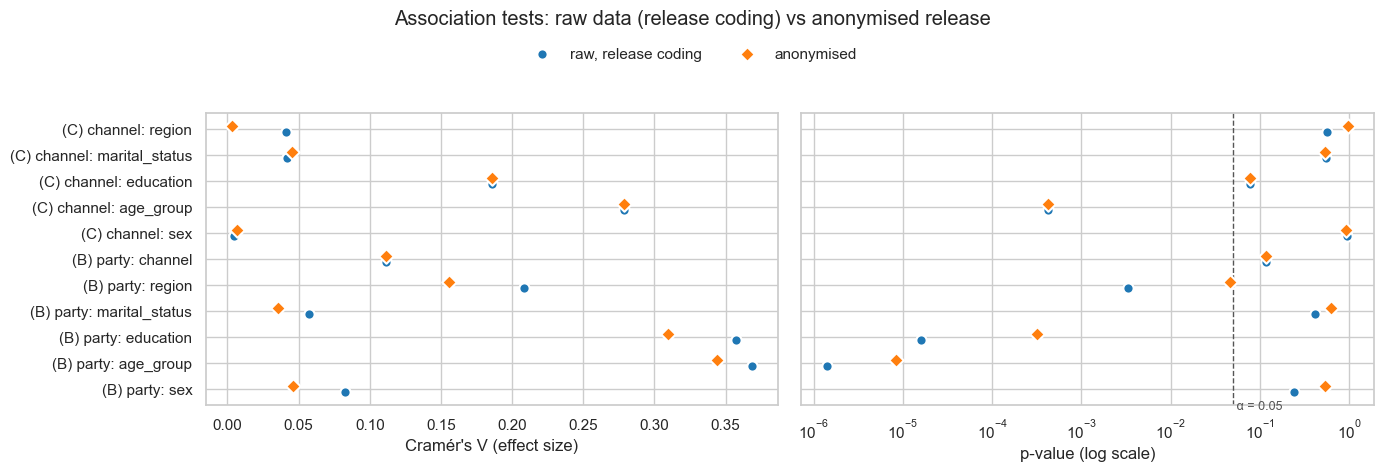

In [10]:
def stack(tables, family):
    return pd.concat({k: t[["p", "Cramer's V"]] for k, t in tables.items() if k in VERSION_STYLE}, names=["version"]) \
             .reset_index().assign(family=family)


long = pd.concat([stack(B, "(B) party"), stack(C_assoc, "(C) channel")])
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, metric, xlabel in [(axes[0], "Cramer's V", "Cramér's V (effect size)"),
                           (axes[1], "p", "p-value (log scale)")]:
    labels = [f"{f}: {a}" for f, a in long[["family", "attribute"]].drop_duplicates().itertuples(index=False)]
    ypos = {lab: i for i, lab in enumerate(labels)}
    for version, style in VERSION_STYLE.items():
        d = long[long["version"] == version]
        y = [ypos[f"{f}: {a}"] + (-0.12 if version == "raw, release coding" else 0.12) for f, a in zip(d["family"], d["attribute"])]
        ax.scatter(d[metric], y, s=55, label=version, edgecolor="white", linewidth=1.5, zorder=3, **style)
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels); ax.invert_yaxis()
    ax.set_xlabel(xlabel)
    if metric == "p":
        ax.set_xscale("log"); ax.axvline(ALPHA, color="#555555", ls="--", lw=1)
        ax.text(ALPHA, -0.8, " α = 0.05", color="#555555", fontsize=9)
handles, names = axes[0].get_legend_handles_labels()
fig.legend(handles, names, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 0.93))
fig.suptitle("Association tests: raw data (release coding) vs anonymised release")
plt.tight_layout(rect=(0, 0, 1, 0.88)); plt.show()

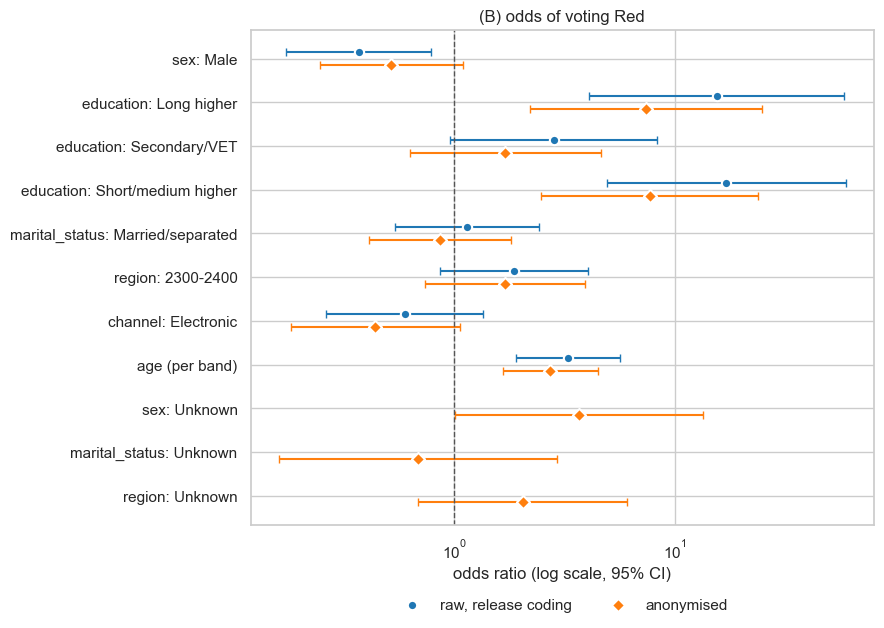

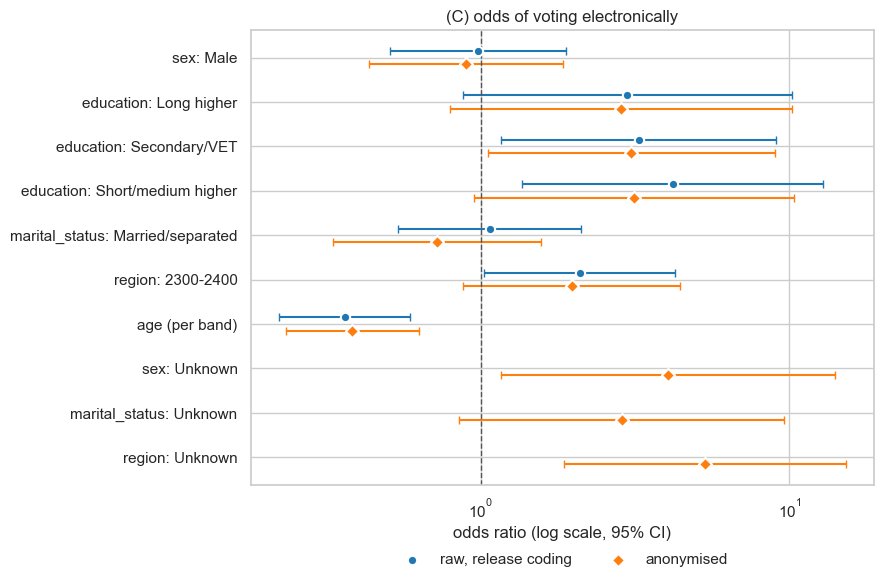

In [11]:
def pretty(term):
    m = re.match(r"C\((\w+).*\)\[T\.(.+)\]", term)
    return f"{m.group(1)}: {m.group(2)}" if m else term.replace("age_rank", "age (per band)")


def forest_compare(tables, title):
    terms = list(tables["raw, release coding"].index)
    terms += [t for t in tables["anonymised"].index if t not in terms]
    fig, ax = plt.subplots(figsize=(9, 0.45 * len(terms) + 1.5))
    for version, style in VERSION_STYLE.items():
        t = tables[version].reindex(terms)
        y = np.arange(len(terms)) + (-0.15 if version == "raw, release coding" else 0.15)
        ax.errorbar(t["OR"], y, xerr=[t["OR"] - t["CI low"], t["CI high"] - t["OR"]], fmt="none",
                    ecolor=style["color"], capsize=3, lw=1.5)
        ax.scatter(t["OR"], y, s=45, label=version, edgecolor="white", linewidth=1.5, zorder=3, **style)
    ax.axvline(1, color="#555555", ls="--", lw=1); ax.set_xscale("log")
    ax.set_yticks(range(len(terms))); ax.set_yticklabels([pretty(t) for t in terms]); ax.invert_yaxis()
    ax.set_xlabel("odds ratio (log scale, 95% CI)"); ax.set_title(title)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
    plt.tight_layout(); plt.show()


forest_compare(B_logit, "(B) odds of voting Red")
forest_compare(C_logit, "(C) odds of voting electronically")

### Applying the "too large" rule

In [12]:
def verdict_rows(question, tables, p_col, v_col=None):
    a, b = tables["raw, release coding"], tables["anonymised"]
    rows = []
    for term in a.index.union(b.index):
        pa, pb = a[p_col].get(term, np.nan), b[p_col].get(term, np.nan)
        r = {"question": question, "test / term": term, "p raw (release coding)": pa, "p anonymised": pb,
             "verdict flips": (pa < ALPHA) != (pb < ALPHA) if pd.notna(pa) and pd.notna(pb) else np.nan}
        if v_col:
            r["|ΔV|"] = abs(a[v_col].get(term, np.nan) - b[v_col].get(term, np.nan))
        rows.append(r)
    return rows


checks = pd.DataFrame(
    verdict_rows("A exact multinomial", A, "p exact multinomial")
    + verdict_rows("A binomial", A, "p binomial")
    + verdict_rows("B chi2", B, "p", "Cramer's V")
    + verdict_rows("B chi2 (Holm)", B, "p Holm")
    + verdict_rows("B Mann-Whitney", B_num, "p")
    + verdict_rows("B logistic", B_logit, "p")
    + verdict_rows("C chi2", C_assoc, "p", "Cramer's V")
    + verdict_rows("C chi2 (Holm)", C_assoc, "p Holm")
    + verdict_rows("C Mann-Whitney", C_num, "p")
    + verdict_rows("C logistic", C_logit, "p")
)
problems = checks[(checks["verdict flips"] == True) | (checks["|ΔV|"] > 0.10)]
print(f"{len(checks)} tests compared, {int((checks['verdict flips'] == True).sum())} verdict flips, "
      f"{int((checks['|ΔV|'] > 0.10).sum())} effect-size changes > 0.10")
problems.round(4) if len(problems) else "No differences above the threshold."

57 tests compared, 4 verdict flips, 0 effect-size changes > 0.10


,question,test / term,p raw (release coding),p anonymised,verdict flips,|ΔV|
20,B chi2 (Holm),region,0.0135,0.1829,True,NaN
32,B logistic,"C(sex, Treatment('Female'))[T.Male]",0.0101,0.0867,True,NaN
49,C logistic,"C(education, Treatment('Primary'))[T.Short/med...",0.0123,0.0603,True,NaN
52,C logistic,C(region)[T.2300-2400],0.0423,0.0996,True,NaN


## Conclusion

**(A) Survey vs official results: same conclusion.** No significant difference for electronic votes, paper votes or all votes, in either version. Channel-level counts are identical because the channel is never blanked and party swaps stay within channel × region. The per-ZIP tests from Step 1 are replaced by per-region tests, which are also non-significant in every version.

**(B) Party vs demographics: main findings kept, two lost.**
* Kept: **age** and **education** are strongly associated with party in every version (Cramér's V 0.34 and 0.31 in the release vs 0.37 and 0.36 raw), both as χ² tests and in the logistic regression.
* Lost: **region**. Raw p = 0.003 becomes 0.046, and after Holm correction (as used in Step 1) 0.013 becomes 0.18, so it is **no longer significant**. Region is the most often blanked column (33 of 200 values).
* Lost: the **adjusted sex effect** (men less likely to vote Red). The odds ratio moves from 0.37 to 0.52 and p from 0.010 to 0.087. Testing variants shows this comes from the party swapping.
* Sex, marital status and channel are not significant in any version.

**(C) Channel vs demographics: univariate results identical, regression weaker.**
* Age is the only significant attribute in every version. Its p-values and effect sizes are identical, because age, education and channel are never blanked.
* In the logistic regression, age stays significant, but *short/medium higher education* (p 0.012 → 0.060) and *region* (0.042 → 0.100) do not. Both were close to 0.05. Region was not a Step 1 finding; it only became significant with the release coding.
* The *Unknown* levels are significant (unknown region: OR 5.3 for e-voting). The blanks are **not random**: the greedy suppression mostly blanks rows of e-voters, the rarer group, to protect them. Anyone analysing the release should know this.

**Coarser coding alone** (Step 1 → release coding) already costs some detail: ZIP 2300's effect on party is diluted in its region, and *long higher education* for channel drops just above 0.05.

**Verdict.** By the rule set at the top, the differences are **too large**: 3 regression flips plus the Holm flip for region. Following Step 3, the anonymisation should be revisited in Step 2. Variants tested on the same rule:

| Variant | Blanked cells | Rows with ≥ 80 % one party | Flips | Step 1 findings lost |
|---|---|---|---|---|
| current v2 (k = 5, swap 10 %) | 66 | 83 | 3 + region (Holm) | region → party, adjusted sex → party |
| no swap | 66 | 89 | 3 + region (Holm) | region → party |
| drop marital status | 17 | 68 | 4 | adjusted sex → party |
| drop marital status, no swap | 16 | 71 | 3 | none of the univariate or (B) findings; only borderline (C) regression terms |
| drop marital + max 75 % one party | 30 | 0 | 4 + region (Holm) | region → party, adjusted sex → party |

No variant reaches zero flips: the (C) regression terms near p = 0.05 flip under any change. The rule is therefore stricter than the data can support, and the realistic goal is to keep the Step 1 findings. *Drop marital status, no swap* does that best, but it can no longer answer questions about marital status (not significant in Step 1) and it gives up the swapping's protection.